# Неделя 16. SHAP, LIME и первый нейрон

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** получить реальные SHAP и LIME объяснения, проверить аддитивность и локальную точность, отделить объяснение модели от причинности и сделать forward pass нейрона.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_16_explainability_nn'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'diabetes_raw.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (331, 10), 'sealed_test': (111, 10)}


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
sample_id,,,,,,,,,,
16,47,1,30.3,109.0,207,100.2,70.0,3.00,5.2149,98
408,66,1,21.7,126.0,212,127.8,45.0,4.71,5.2781,101
432,51,1,31.5,93.0,231,144.0,49.0,4.70,5.2523,117


## 1. Что и на каких данных объясняем

Объяснять модель до проверки качества опасно: убедительное объяснение может
сопровождать слабый прогноз. На небольшом наборе обучим ограниченный Random Forest.
Для объяснений используем validation внутри train; фоновые данные — только fit.
Test сохраняем для финальной оценки, без подбора по нему признаков.


,count,mean,std,min,25%,50%,75%,max
age,248.0,48.60,12.99,19.0,39.00,50.00,58.00,79.00
sex,248.0,1.46,0.50,1.0,1.00,1.00,2.00,2.00
bmi,248.0,26.66,4.50,18.1,23.50,25.85,29.50,41.30
bp,248.0,94.91,14.16,62.0,84.00,93.00,105.00,133.00
s1,248.0,188.68,34.62,110.0,162.00,187.00,209.25,301.00
s2,248.0,114.27,30.58,41.6,93.75,113.20,131.60,215.00
s3,248.0,50.11,12.88,22.0,41.00,48.00,57.00,99.00
s4,248.0,4.02,1.27,2.0,3.00,4.00,5.00,8.28
s5,248.0,4.65,0.53,3.5,4.28,4.59,4.97,6.11
s6,248.0,91.98,11.63,58.0,84.00,92.00,98.00,124.00


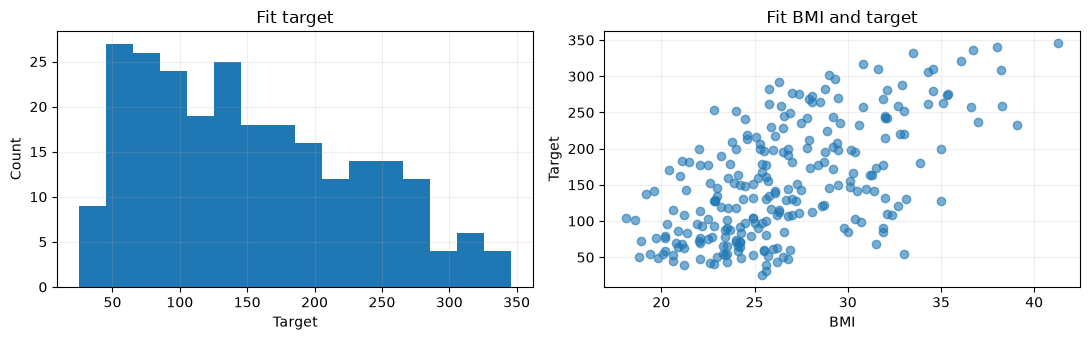

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED + 1)
assert set(X_fit.index).isdisjoint(X_val.index)
display(X_fit.describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
y_fit.hist(bins=16, ax=axes[0]); axes[0].set(title="Fit target", xlabel="Target", ylabel="Count")
axes[1].scatter(X_fit.bmi, y_fit, alpha=0.6); axes[1].set(title="Fit BMI and target", xlabel="BMI", ylabel="Target")
plt.tight_layout(); plt.show()


## 2. Фиксированная модель и baseline

На этой неделе задача — интерпретация, поэтому параметры объявлены заранее,
а не оптимизируются по результатам объяснений. Референсное распределение SHAP задаётся
train-статистиками листьев в режиме tree_path_dependent. Отдельную фоновую
выборку не передаём. Ограничиваем количество деревьев и объясняемых строк для CPU.


In [4]:
model = RandomForestRegressor(n_estimators=90, max_depth=5, min_samples_leaf=5,
                               max_features=0.8, random_state=SEED, n_jobs=1)
model.fit(X_fit, y_fit)
baseline = DummyRegressor().fit(X_fit, y_fit)
print("Validation RF RMSE:", np.sqrt(mean_squared_error(y_val, model.predict(X_val))))
print("Validation baseline RMSE:", np.sqrt(mean_squared_error(y_val, baseline.predict(X_val))))
explain_rows = X_val.iloc[:20].copy()


Validation RF RMSE: 58.79469701301004
Validation baseline RMSE: 74.11698960240876


## 3. SHAP: аддитивные вклады в прогноз

$$f(x)=\phi_0+\sum_{j=1}^{p}\phi_j(x).$$

SHAP распределяет отличие прогноза от фонового значения между признаками
относительно выбранной игры/фонового распределения. Для регрессора объясняем
выход в единицах target. `feature_perturbation='tree_path_dependent'` использует число train-наблюдений
в путях/листьях обученных деревьев как референсное распределение. Это явный
выбор способа объяснения, **не** доказательство причинного эффекта.


In [5]:
import shap
print("SHAP", shap.__version__)
shap_explainer = shap.TreeExplainer(model,
    feature_perturbation="tree_path_dependent", model_output="raw")
explanation = shap_explainer(explain_rows, check_additivity=True)
reconstructed_prediction = np.asarray(explanation.base_values) + explanation.values.sum(axis=1)
actual_prediction = model.predict(explain_rows)
assert explanation.values.shape == explain_rows.shape
assert np.allclose(reconstructed_prediction, actual_prediction, atol=1e-4)
print("Максимальная ошибка аддитивности:", np.max(np.abs(reconstructed_prediction-actual_prediction)))


SHAP 0.54.1
Максимальная ошибка аддитивности: 8.526512829121202e-14


## 4. Локальная waterfall и глобальное среднее

Waterfall объясняет **один** прогноз. Среднее абсолютных SHAP по 20 validation
строкам описывает именно эту небольшую выборку. Оно не показывает направление
эффекта и не является универсальной важностью признака для всех моделей.


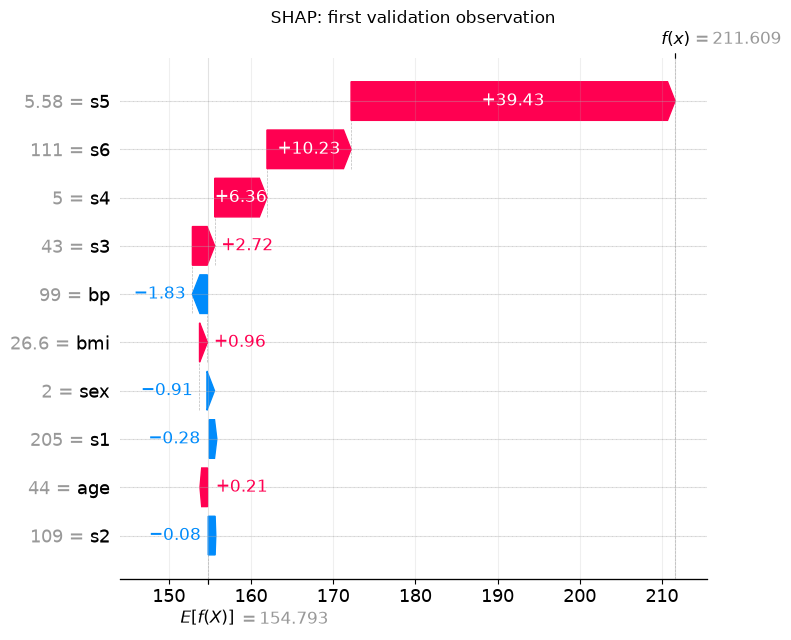

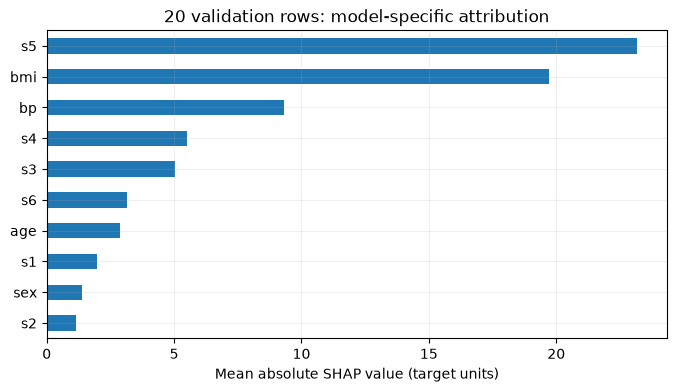

In [6]:
shap.plots.waterfall(explanation[0], max_display=10, show=False)
plt.title("SHAP: first validation observation"); plt.tight_layout(); plt.show()
mean_abs_shap = pd.Series(np.abs(explanation.values).mean(axis=0), index=X_fit.columns).sort_values()
mean_abs_shap.plot.barh()
plt.xlabel("Mean absolute SHAP value (target units)")
plt.title("20 validation rows: model-specific attribution"); plt.show()


## 5. Значение признака и его вклад

Посмотрим BMI и SHAP(BMI). Рассеяние может отражать взаимодействия и другие
признаки. График нельзя читать как «если вмешаться и изменить BMI на столько,
реальный исход изменится на столько».


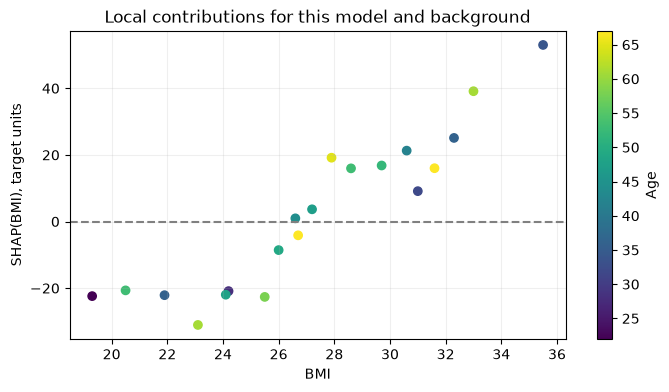

,feature,value,SHAP
3,bp,99.0000,-1.825738
1,sex,2.0000,-0.905229
4,s1,205.0000,-0.284261
5,s2,109.0000,-0.078092
0,age,44.0000,0.207393
2,bmi,26.6000,0.959536
6,s3,43.0000,2.715247
7,s4,5.0000,6.359079
9,s6,111.0000,10.234926
8,s5,5.5797,39.432855


In [7]:
feature_position = list(X_fit.columns).index("bmi")
plt.scatter(explain_rows.bmi, explanation.values[:, feature_position], c=explain_rows.age, cmap="viridis")
plt.axhline(0, color="gray", ls="--")
plt.colorbar(label="Age"); plt.xlabel("BMI"); plt.ylabel("SHAP(BMI), target units")
plt.title("Local contributions for this model and background"); plt.show()
display(pd.DataFrame({"feature": X_fit.columns,
                      "value": explain_rows.iloc[0].to_numpy(),
                      "SHAP": explanation.values[0]}).sort_values("SHAP"))


## 6. LIME: локальная приближённая модель

LIME генерирует окрестность точки, запрашивает исходную модель и обучает
простую взвешенную аппроксимацию:
$$\arg\min_g\sum_z\pi_x(z)(f(z)-g(z))^2+\Omega(g).$$

Используем настоящую библиотеку `lime`, режим regression и train-статистики.
LIME не обязан воспроизводить прогноз точно: оценим локальный R² и ошибку
аппроксимации в выбранной точке. Коэффициенты LIME не равны SHAP-вкладам.


In [8]:
from lime.lime_tabular import LimeTabularExplainer
def predict_for_lime(array):
    # Сохраняем имена признаков и правильный порядок столбцов.
    return model.predict(pd.DataFrame(array, columns=X_fit.columns))
lime_explainer = LimeTabularExplainer(X_fit.to_numpy(),
    feature_names=list(X_fit.columns), mode="regression", discretize_continuous=True,
    random_state=SEED)
observation = X_val.iloc[0].to_numpy()
lime_explanation = lime_explainer.explain_instance(observation, predict_for_lime,
                                                 num_features=7, num_samples=1500)
actual = float(predict_for_lime(observation.reshape(1, -1))[0])
local_prediction = float(np.asarray(lime_explanation.local_pred).reshape(-1)[0])
display(pd.DataFrame(lime_explanation.as_list(), columns=["local condition", "LIME weight"]))
print({"model_prediction": actual, "local_surrogate_prediction": local_prediction,
       "absolute_local_error": abs(actual-local_prediction), "weighted_local_R2": lime_explanation.score})
assert np.isfinite([actual, local_prediction, lime_explanation.score]).all()


,local condition,LIME weight
0,s5 > 4.97,40.738126
1,25.85 < bmi <= 29.50,14.114138
2,s6 > 98.00,6.883595
3,4.00 < s4 <= 5.00,4.837149
4,187.00 < s1 <= 209.25,-4.461542
5,93.75 < s2 <= 113.20,-2.523644
6,41.00 < s3 <= 48.00,2.213089


{'model_prediction': 211.60917455945963, 'local_surrogate_prediction': 201.52714266679902, 'absolute_local_error': 10.08203189266061, 'weighted_local_R2': 0.28393970529876167}


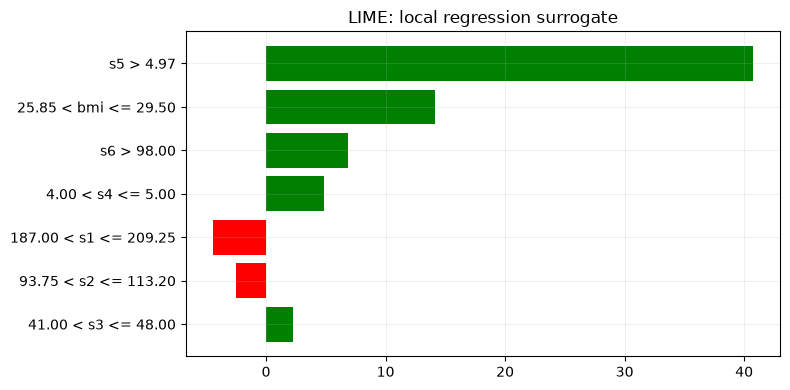

In [9]:
lime_explanation.as_pyplot_figure()
plt.title("LIME: local regression surrogate"); plt.tight_layout(); plt.show()


## 7. Проверка устойчивости LIME

Повторим объяснение при двух seeds с неизменной моделью. Различия — сигнал,
что локальная аппроксимация чувствительна к выборке соседей. На коррелированных
признаках искусственные комбинации могут быть нетипичными для реальных данных.
Не выбираем seed только ради удобной истории.


In [10]:
stability = []
for seed in [42, 43, 44]:
    local = LimeTabularExplainer(X_fit.to_numpy(), feature_names=list(X_fit.columns),
        mode="regression", discretize_continuous=True, random_state=seed)
    result = local.explain_instance(observation, predict_for_lime, num_features=7, num_samples=1500)
    stability.append({"seed": seed, "local_R2": result.score,
        "local_error": abs(actual-float(np.asarray(result.local_pred).reshape(-1)[0])),
        "top_condition": max(result.as_list(), key=lambda pair: abs(pair[1]))[0]})
display(pd.DataFrame(stability))


,seed,local_R2,local_error,top_condition
0,42,0.283940,10.082032,s5 > 4.97
1,43,0.273963,12.045246,s5 > 4.97
2,44,0.265313,10.523628,s5 > 4.97


## 8. Финальная оценка зафиксированной модели

Модель оставляем обученной на fit, потому что именно её объясняли. Если
переобучить её на всём train, объяснения потребуется вычислить заново.
Test измеряет качество этой конкретной модели, а SHAP/LIME описывают её поведение.


In [11]:
final_prediction = model.predict(X_test)
display(pd.DataFrame([
    {"model": "mean baseline", "RMSE": np.sqrt(mean_squared_error(y_test, baseline.predict(X_test)))},
    {"model": "explained RF", "RMSE": np.sqrt(mean_squared_error(y_test, final_prediction))}]))
print("Final RF MAE:", mean_absolute_error(y_test, final_prediction))
assert final_prediction.shape == y_test.shape


,model,RMSE
0,mean baseline,74.777684
1,explained RF,51.471684


Final RF MAE: 41.31436644891894


## 9. Переход к нейронным сетям: нейрон как знакомая модель

$$z=Xw+b,\qquad a=\sigma(z).$$

С линейным выходом это регрессия; с sigmoid — знакомая логистическая модель.
Несколько нейронов образуют слой. Без нелинейности несколько линейных слоёв
сворачиваются в одно линейное преобразование. Ниже данные **синтетические**:
они нужны для геометрии, а не для ещё одного клинического эксперимента.


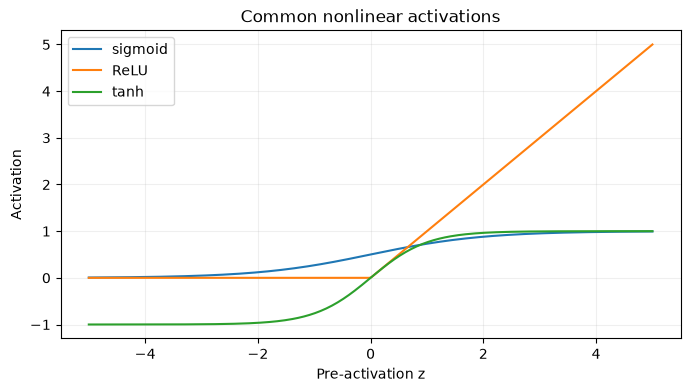

In [12]:
z = np.linspace(-5, 5, 300)
sigmoid = lambda values: 1/(1+np.exp(-np.clip(values, -50, 50)))
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, np.maximum(0, z), label="ReLU")
plt.plot(z, np.tanh(z), label="tanh")
plt.xlabel("Pre-activation z"); plt.ylabel("Activation"); plt.title("Common nonlinear activations")
plt.legend(); plt.show()


## 10. Один forward pass и форма тензоров

XOR — четыре точки, которые нельзя разделить одной прямой. Скрытый слой
позволяет нелинейное преобразование. Сейчас веса выбраны вручную только
для демонстрации форм и вычислений; **сеть ещё не обучена**. Backprop — следующая неделя.


In [13]:
xor_X = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
xor_y = np.array([[0.], [1.], [1.], [0.]])
W1 = np.array([[1.0, -1.0, 0.5], [-1.0, 1.0, 0.5]])
b1 = np.array([0.0, 0.0, -0.3])
W2 = np.array([[1.0], [1.0], [-1.0]])
b2 = np.array([-0.1])
hidden = np.maximum(0, xor_X @ W1 + b1)
logits = hidden @ W2 + b2
probability = sigmoid(logits)
loss = np.mean(np.logaddexp(0, logits)-xor_y*logits)
assert hidden.shape == (4, 3) and probability.shape == (4, 1)
assert np.isfinite(loss) and np.all((probability >= 0) & (probability <= 1))
display(pd.DataFrame({"x1": xor_X[:, 0], "x2": xor_X[:, 1],
                      "target": xor_y[:, 0], "untrained_probability": probability[:, 0]}))
print("Loss до обучения:", loss)


,x1,x2,target,untrained_probability
0,0.0,0.0,0.0,0.475021
1,0.0,1.0,1.0,0.668188
2,1.0,0.0,1.0,0.668188
3,1.0,1.0,0.0,0.310026


Loss до обучения: 0.45546735594806603


## Что перенести в отчёт

Для объяснения укажите модель, версию библиотеки, фоновые данные, конкретную
выборку и шкалу output. Проверьте additivity SHAP и surrogate fidelity LIME.
Укажите, какие изменения модели потребуют новых объяснений. Для нейрона
запишите размерности X, W1, hidden, W2 и объясните роль активации.

Источники: [Lundberg & Lee, SHAP](https://arxiv.org/abs/1705.07874),
[SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html),
[Ribeiro et al., LIME](https://arxiv.org/abs/1602.04938),
[официальный LIME repository](https://github.com/marcotcr/lime),
[Stanford CS231n neural networks](https://cs231n.github.io/neural-networks-1/).
